In [31]:
import pandas as pd
import numpy as np
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report,accuracy_score
from sklearn import set_config
from sklearn.model_selection import train_test_split
set_config(transform_output='pandas')

In [ ]:
data=make_moons()
x,y=make_moons(random_state=42,noise=0.30,n_samples=3000)

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


model_lr=LogisticRegression(max_iter=10)
model_lr.fit(X_train_scaled,y_train)
y_pred=model_lr.predict(X_test_scaled)
print(classification_report(y_test,y_pred))
log_train_acc = accuracy_score(y_train,model_lr.predict(X_train_scaled))
log_test_acc = accuracy_score(y_test, model_lr.predict(X_test_scaled))

print("1. BASELINE: LOGISTIC REGRESSION")
print(f"   Train Accuracy : {log_train_acc * 100:.2f}%")
print(f"   Test Accuracy  : {log_test_acc * 100:.2f}%")

              precision    recall  f1-score   support

           0       0.87      0.83      0.85       328
           1       0.81      0.85      0.83       272

    accuracy                           0.84       600
   macro avg       0.84      0.84      0.84       600
weighted avg       0.84      0.84      0.84       600

1. BASELINE: LOGISTIC REGRESSION
   Train Accuracy : 85.00%
   Test Accuracy  : 84.17%


In [39]:


stump_model = DecisionTreeClassifier(max_depth=1, random_state=42)
stump_model.fit(X_train_scaled, y_train)
stump_train_acc=accuracy_score(y_train,model_lr.predict(X_train_scaled))
stump_test_acc = accuracy_score(y_test, stump_model.predict(X_test))

print("2. WEAK LEARNER: SINGLE DECISION STUMP (max_depth=1)")
print(f"   Train Accuracy  : {stump_train_acc * 100:.2f}%")
print(f"   Test Accuracy  : {stump_test_acc * 100:.2f}%")

2. WEAK LEARNER: SINGLE DECISION STUMP (max_depth=1)
   Train Accuracy  : 85.00%
   Test Accuracy  : 82.00%


c:\Users\VP\anaconda3\envs\ML\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [51]:
ada_model=AdaBoostClassifier(learning_rate=0.5,
                             random_state=42,
                             estimator=DecisionTreeClassifier(max_depth=3),
                             n_estimators=100)
ada_model.fit(X_train, y_train)

ada_train_acc = accuracy_score(y_train, ada_model.predict(X_train))
ada_test_acc = accuracy_score(y_test, ada_model.predict(X_test))

print("3. ENSEMBLE: ADABOOST CLASSIFIER (100 Stumps Combined)")
print(f"   Train Accuracy : {ada_train_acc * 100:.2f}%")
print(f"   Test Accuracy  : {ada_test_acc * 100:.2f}%")

3. ENSEMBLE: ADABOOST CLASSIFIER (100 Stumps Combined)
   Train Accuracy : 91.42%
   Test Accuracy  : 89.67%


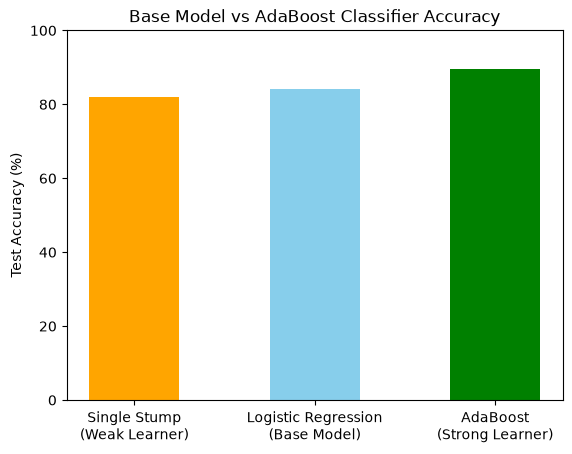

In [54]:
import matplotlib.pyplot as plt

models = ['Single Stump\n(Weak Learner)', 'Logistic Regression\n(Base Model)', 'AdaBoost\n(Strong Learner)']

scores = [stump_test_acc * 100, log_test_acc * 100, ada_test_acc * 100]

plt.bar(models, scores, color=['orange', 'skyblue', 'green'], width=0.5,data=True)

plt.title('Base Model vs AdaBoost Classifier Accuracy')
plt.ylabel('Test Accuracy (%)')
plt.ylim(0, 100) 

plt.show()